**CCGT Case Study 4: Design Optimization of the Steam Cycle**

The gas turbine is usually bought as a standard machine; the HRSG and steam cycle are designed around its exhaust. Three design questions:

1. **Drum pressure:** a higher pressure gives more work per kg of steam, but less steam (the boiling plateau rises against the gas line) and a wetter turbine exhaust.
2. **Optimum steam conditions:** IPOPT maximizes the net power over the drum pressure and the superheated steam temperature, with the exhaust quality (blade erosion) and material limits as constraints.
3. **Pinch:** a smaller pinch makes more steam but needs much more heat transfer surface; the best pinch balances the extra revenue against the HRSG cost.

All three use the `"targets"` mode: TIT 1350 °C, with the steam flow set by the pinch.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ccgt import setup_ccgt_model, set_mode, ccgt_results
from ccgt_case_studies import solve

pd.set_option("display.max_columns", 40)
model, results = setup_ccgt_model()
set_mode(model, "targets")
solve(model)
design = ccgt_results(model)
print("Design net power {0:.0f} kW".format(design["Plant net power (kW)"]))

2026-11-12 16:52:48 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:52:48 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:52:48 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:52:48 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_in[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:52:48 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_out[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:52:48 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.properties_isentropic[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


... (43 outputs left out)

2026-11-12 16:52:48 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.economizer.cold_side.heat


2026-11-12 16:52:48 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.condenser.control_volume.heat


The DOF is 0


Design net power 27113 kW


## 1. Drum pressure sweep

The feed pump outlet pressure is varied from 20 to 120 bar (the drum is 1 bar lower); the economizer approach (10 K), the steam temperature (500 °C) and the pinch (10 K) stay fixed.

In [3]:
from ccgt_case_studies import drum_pressure_sweep

dp = drum_pressure_sweep(model)
cols = ["Plant net power (kW)", "Steam turbine (kW)", "Steam flow (kg/s)", "Drum saturation temperature (C)",
        "Stack temperature (C)", "Steam turbine exhaust quality", "HRSG area (m2)"]
dp[cols].round(3)

,Plant net power (kW),Steam turbine (kW),Steam flow (kg/s),Drum saturation temperature (C),Stack temperature (C),Steam turbine exhaust quality,HRSG area (m2)
Pump outlet pressure (bar),,,,,,,
20,26245.331,7647.713,7.977,209.798,92.822,0.973,6302.133
30,26577.544,7990.007,7.936,231.980,97.800,0.949,6496.052
40,26796.318,8218.870,7.918,248.857,101.100,0.931,6669.314
50,26959.112,8391.795,7.916,262.681,103.335,0.917,6836.321
62,27113.252,8558.190,7.928,276.666,104.989,0.903,7039.836
70,27200.549,8653.738,7.943,284.857,105.581,0.895,7181.909
80,27298.537,8762.151,7.970,294.131,105.818,0.886,7370.967
90,27388.319,8862.509,8.004,302.544,105.540,0.878,7577.092
100,27473.057,8957.996,8.045,310.259,104.772,0.870,7805.312


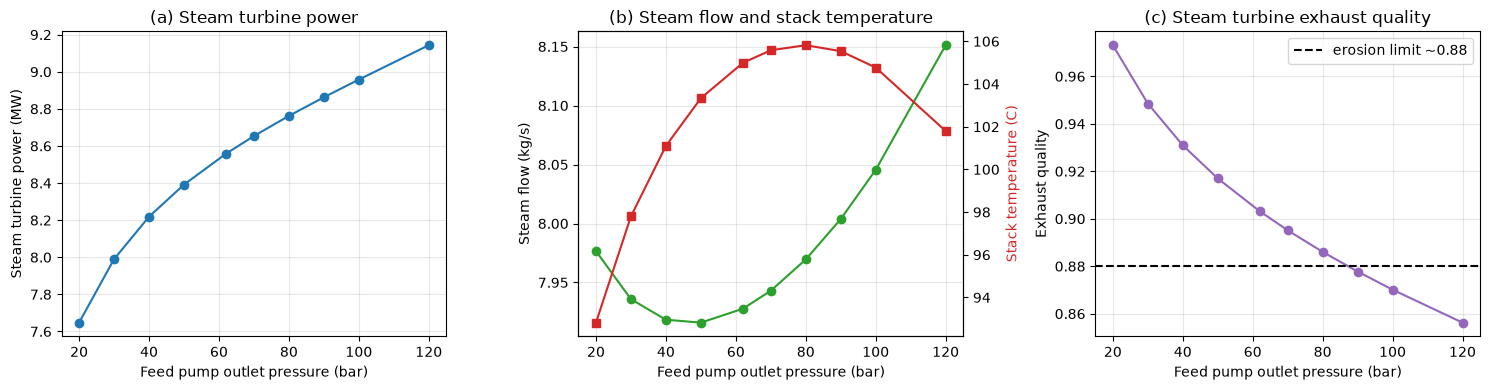

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(dp.index, dp["Steam turbine (kW)"] / 1e3, "o-")
axes[0].set_ylabel("Steam turbine power (MW)")
axes[0].set_title("(a) Steam turbine power")
axes[1].plot(dp.index, dp["Steam flow (kg/s)"], "o-", color="tab:green", label="Steam flow")
axes[1].set_ylabel("Steam flow (kg/s)")
ax2 = axes[1].twinx()
ax2.plot(dp.index, dp["Stack temperature (C)"], "s-", color="tab:red")
ax2.set_ylabel("Stack temperature (C)", color="tab:red")
axes[1].set_title("(b) Steam flow and stack temperature")
axes[2].plot(dp.index, dp["Steam turbine exhaust quality"], "o-", color="tab:purple")
axes[2].axhline(0.88, color="k", ls="--", label="erosion limit ~0.88")
axes[2].set_ylabel("Exhaust quality")
axes[2].set_title("(c) Steam turbine exhaust quality")
axes[2].legend()
for ax in axes:
    ax.set_xlabel("Feed pump outlet pressure (bar)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The steam turbine output keeps rising with pressure, but with diminishing returns, and the exhaust gets wetter: at 500 °C the 0.88 quality limit is reached at about 85–90 bar. The steam flow first falls and then rises again, because the economizer and evaporator duties shift as the saturation temperature rises. A higher pressure also needs more HRSG surface.

## 2. Optimum drum pressure and steam temperature

Maximize the net power over the pump outlet pressure (20–140 bar) and the steam temperature, subject to:
* steam turbine exhaust quality ≥ 0.88,
* steam temperature ≤ 540 °C (low alloy steel superheater tubes),
* steam temperature at least 25 K below the GT exhaust (superheater approach).

In [5]:
from ccgt_case_studies import optimize_steam_conditions, restore_steam_design

opt = optimize_steam_conditions(model, max_steam_T=540.0, min_exhaust_quality=0.88, min_sh_approach=25.0)
keys = ["Pump outlet pressure (bar)", "Steam temperature (C)", "Steam flow (kg/s)", "Steam turbine (kW)",
        "Plant net power (kW)", "Combined cycle efficiency LHV (%)", "Steam turbine exhaust quality", "Stack temperature (C)"]
design["Pump outlet pressure (bar)"] = 62.0
comparison = pd.DataFrame({"Design": {k: design[k] for k in keys}, "Optimum": {k: opt[k] for k in keys}})
comparison["Change"] = comparison["Optimum"] - comparison["Design"]
print("Converged:", opt["Converged"])
comparison.round(3)

Converged: True


,Design,Optimum,Change
Pump outlet pressure (bar),62.000,116.148,54.148
Steam temperature (C),500.000,540.000,40.000
Steam flow (kg/s),7.928,7.714,-0.213
Steam turbine (kW),8558.189,9057.280,499.091
Plant net power (kW),27113.251,27560.695,447.444
Combined cycle efficiency LHV (%),56.078,57.004,0.925
Steam turbine exhaust quality,0.903,0.880,-0.023
Stack temperature (C),104.989,114.440,9.451


Both limits are active at the optimum: the steam temperature sits at its 540 °C material limit, and the pressure rises until the exhaust quality reaches 0.88 (about 116 bar). The net power gains about 450 kW (about +0.9 points of efficiency). A higher superheat lets the turbine work at a higher pressure without a wet exhaust, which is why large plants add reheat.

## 3. HRSG pinch trade-off

In [6]:
restore_steam_design(model)
from ccgt_case_studies import pinch_study, pinch_economics, optimal_pinch

pz = pinch_study(model)
pz[["Plant net power (kW)", "Steam flow (kg/s)", "Stack temperature (C)", "HRSG area (m2)",
    "Economizer area (m2)", "Evaporator area (m2)", "Superheater area (m2)"]].round(1)

,Plant net power (kW),Steam flow (kg/s),Stack temperature (C),HRSG area (m2),Economizer area (m2),Evaporator area (m2),Superheater area (m2)
Pinch (K),,,,,,,
3,27262.9,8.1,94.5,8951.7,5834.0,2727.1,390.6
4,27241.5,8.0,96.0,8603.3,5552.6,2661.2,389.5
5,27220.2,8.0,97.5,8286.1,5297.7,2600.1,388.3
6,27198.8,8.0,99.0,7995.8,5065.5,2543.1,387.1
8,27156.0,8.0,102.0,7481.9,4657.4,2439.7,384.8
10,27113.3,7.9,105.0,7039.8,4309.6,2347.7,382.5
12,27070.5,7.9,108.0,6654.4,4009.2,2264.9,380.2
15,27006.2,7.8,112.5,6158.9,3627.6,2154.5,376.7
20,26899.1,7.7,120.0,5494.6,3125.4,1998.3,371.0


Halving the pinch from 10 to 5 K adds only about 0.4 % power but 18 % more HRSG surface: the area grows like $1/\Delta T$ as the gas and water lines close in.

The economic optimum depends on the cost of HRSG surface. The annual benefit relative to the 10 K design is

$$\Delta(\text{benefit}) = \Delta P \cdot h \cdot p_{power} - \Delta A \cdot c_{area} \cdot CRF$$

at a power price of 60 $/MWh, 5256 h/yr (60 % capacity factor) and CRF at 8 % over 25 years. An installed cost of 600 $/m² of the model's heat transfer area puts the design HRSG at about $4M.

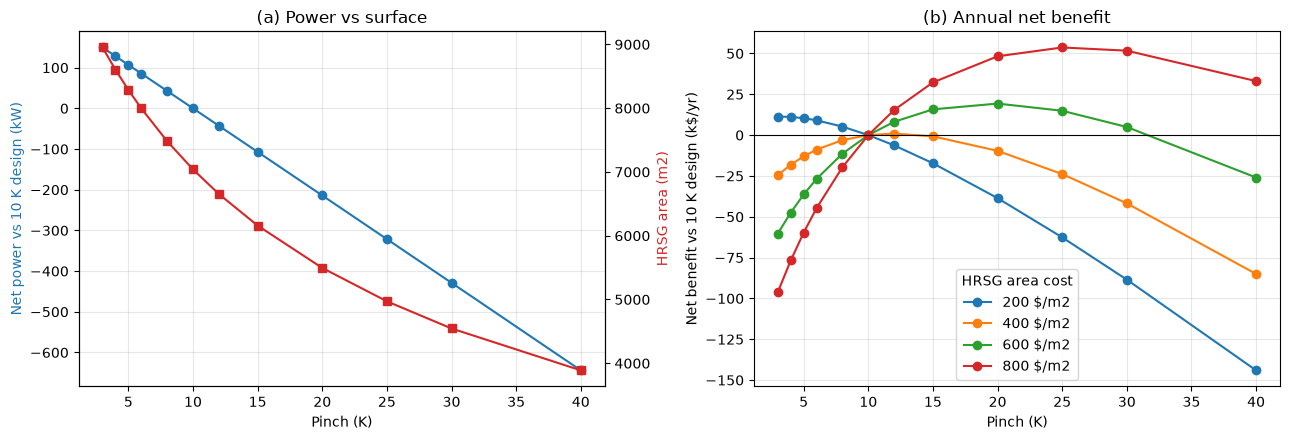

,Optimal pinch (K),Benefit vs 10 K design ($/yr)
HRSG area cost ($/m2),,
200,3.0,11565.4
400,12.1,1230.5
600,18.9,19185.1
800,26.6,53305.1
1000,33.4,100709.5


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(pz.index, (pz["Plant net power (kW)"] - pz.loc[10, "Plant net power (kW)"]), "o-", color="tab:blue")
ax.set_ylabel("Net power vs 10 K design (kW)", color="tab:blue")
ax2 = ax.twinx()
ax2.plot(pz.index, pz["HRSG area (m2)"], "s-", color="tab:red")
ax2.set_ylabel("HRSG area (m2)", color="tab:red")
ax.set_xlabel("Pinch (K)")
ax.set_title("(a) Power vs surface")
ax.grid(alpha=0.3)

ax = axes[1]
for cost in (200, 400, 600, 800):
    b = pinch_economics(pz, area_cost=cost)["Net benefit ($/yr)"]
    ax.plot(pz.index, b / 1e3, "o-", label="{0} $/m2".format(cost))
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Pinch (K)")
ax.set_ylabel("Net benefit vs 10 K design (k$/yr)")
ax.set_title("(b) Annual net benefit")
ax.grid(alpha=0.3)
ax.legend(title="HRSG area cost")
plt.tight_layout()
plt.show()

optimal_pinch(pz).round(1)

**Takeaways**

* The optimum pinch is a matter of cost, not of thermodynamics. Cheap surface (≤ 200 $/m²) pushes the pinch to the edge of the sweep, while the expensive surface of a small plant moves it to 15–30 K. The 10 K design suits about 400 $/m².
* Large plants with cheap power and expensive fuel (a high value per kWh) justify small pinches of 5–8 K and multiple pressure levels. Small plants and peaking duty favour larger pinches and a single pressure, as here.
* The equation-oriented model gives these trade-offs directly: the area follows from the specification, and the optimizer handles the constraints that a sequential simulator would need nested loops for.